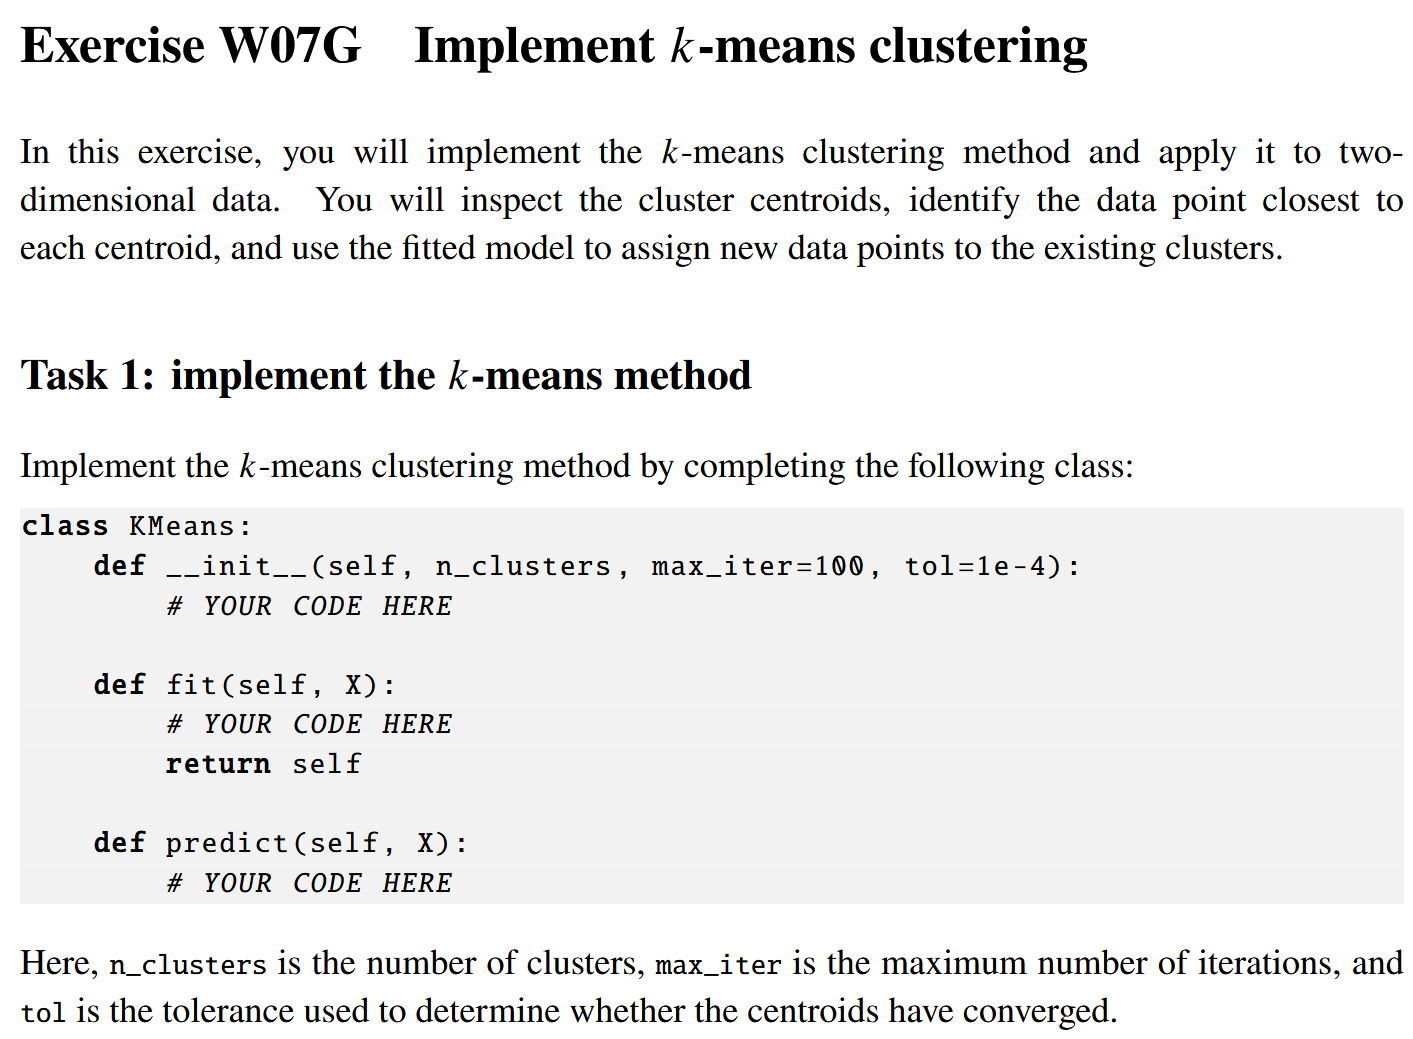
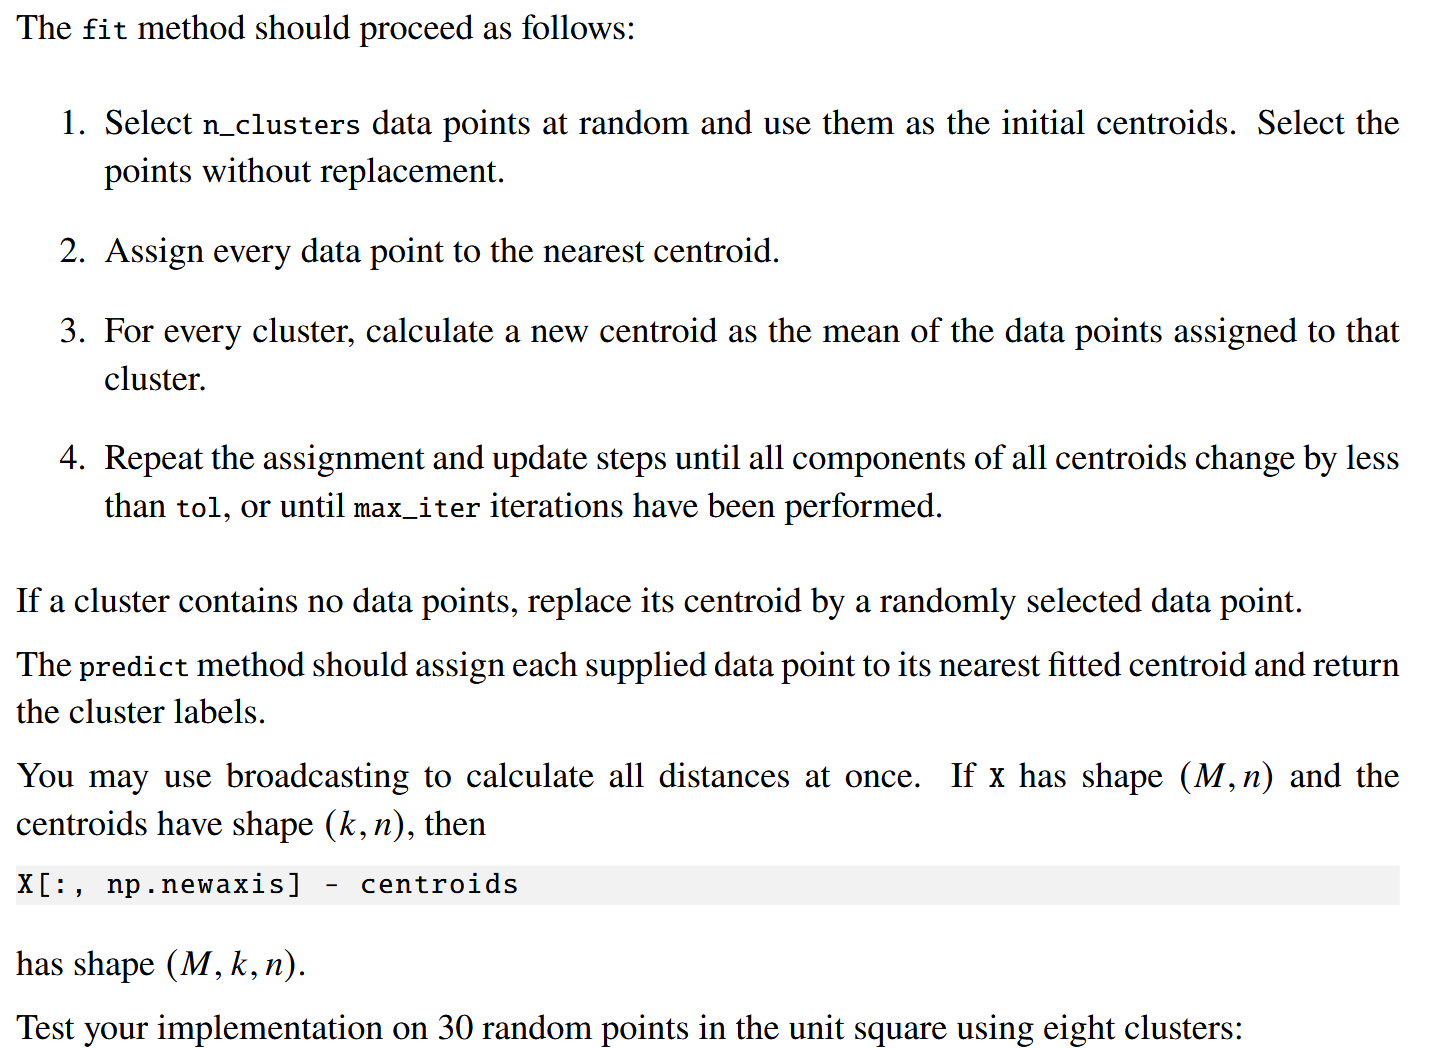
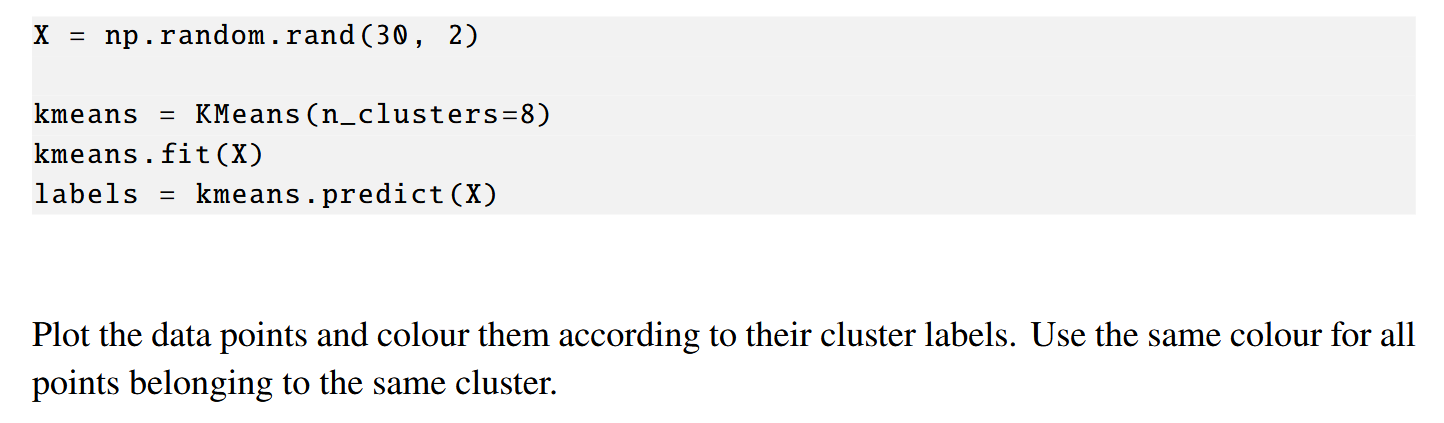
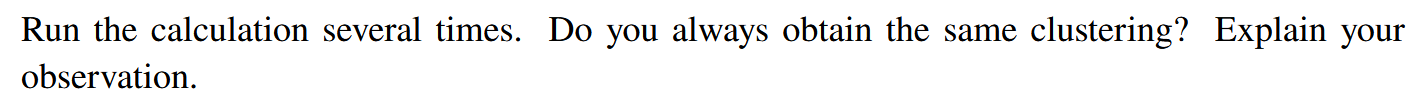

In [2]:
import numpy as np
import matplotlib.pyplot as plt 

class KMeans:
    def __init__(self, n_clusters, max_iter=100, tol=1e-4):
        self.n = n_clusters
        self.max_iter = max_iter
        self.tol = tol

    def fit(self, X):
        # Initialize
        idx = np.random.choice(len(X), self.n, replace=False)
        self.mu = X[idx].copy()

        for _ in range(self.max_iter):
            # Assignment
            self.ci = self.predict(X)

            # Update
            new_mu = np.array([
                X[self.ci == k].mean(axis=0) if np.any(self.ci == k) else self.mu[k]
                for k in range(self.n)
            ])

            # Convergence check
            if np.linalg.norm(new_mu - self.mu) < self.tol:
                self.mu = new_mu
                break

            self.mu = new_mu

        return self

    def predict(self, X):
        ci = []
        for xi in X:
            dist = np.linalg.norm(xi - self.mu, axis=1)
            ci.append(np.argmin(dist))

        return np.array(ci)

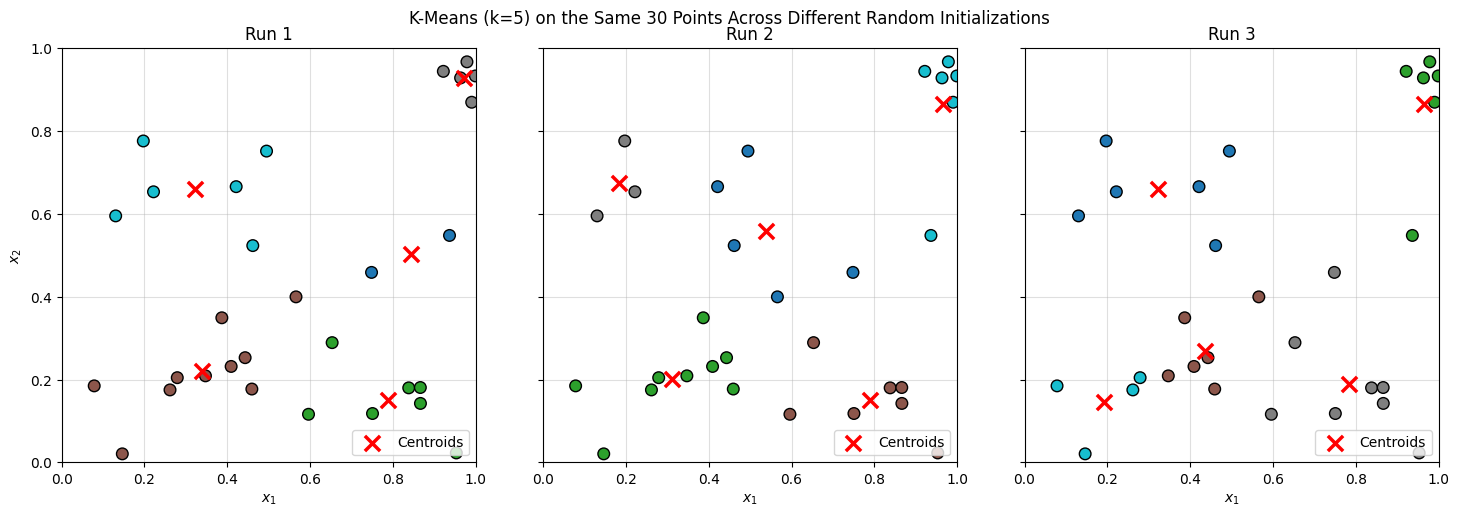

In [5]:
X = np.random.rand(30, 2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

for run_idx, ax in enumerate(axes):
    kmeans = KMeans(n_clusters=5)
    kmeans.fit(X)
    labels = kmeans.predict(X)
    
    # Plot points coloured by their cluster labels
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=70, edgecolor='k', zorder=2)
    
    # Also plot the final cluster centroids as red 'X' markers
    ax.scatter(kmeans.mu[:, 0], kmeans.mu[:, 1], c='red', marker='x', s=120, linewidths=2.5, label='Centroids', zorder=3)
    
    ax.set_title(f'Run {run_idx + 1}')
    ax.set_xlabel('$x_1$')
    if run_idx == 0:
        ax.set_ylabel('$x_2$')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.4)
    ax.legend(loc='lower right')

plt.suptitle('K-Means (k=5) on the Same 30 Points Across Different Random Initializations')
plt.tight_layout()
plt.show()

### Observation & Explanation

**Do you always obtain the same clustering?**
**No** — running the algorithm multiple times (even on the exact same 30 data points `X`) produces different cluster partitions and centroid positions from run to run (in addition to arbitrary color/label permutations).

**Why does this happen?**

1. **Sensitivity to Random Initialization:** In `fit(X)`, the initial $k=8$ centroids are chosen randomly from the dataset (`np.random.choice`). Starting from different initial points changes which points are grouped together in the very first iteration.
2. **Convergence to Local Minima (Greedy Optimization):** K-Means minimizes the within-cluster sum of squared distances (inertia), which is a **non-convex optimization problem** with many local minima. Because Lloyd's algorithm only makes greedy, downhill updates at each step, it gets trapped in whichever local minimum is closest to its random starting centroids rather than finding a single global optimum.
3. **High $k$ Relative to $N$ ($k=8$ for $30$ Uniform Points):** Because $30$ uniformly distributed points in a unit square lack strong, naturally separated clusters—and $8$ clusters is relatively large for $30$ points (only $\sim 3.75$ points per cluster on average)—there are many competing ways to partition the space with nearly identical cost. This makes the final clustering especially sensitive to where the initial centroids land.

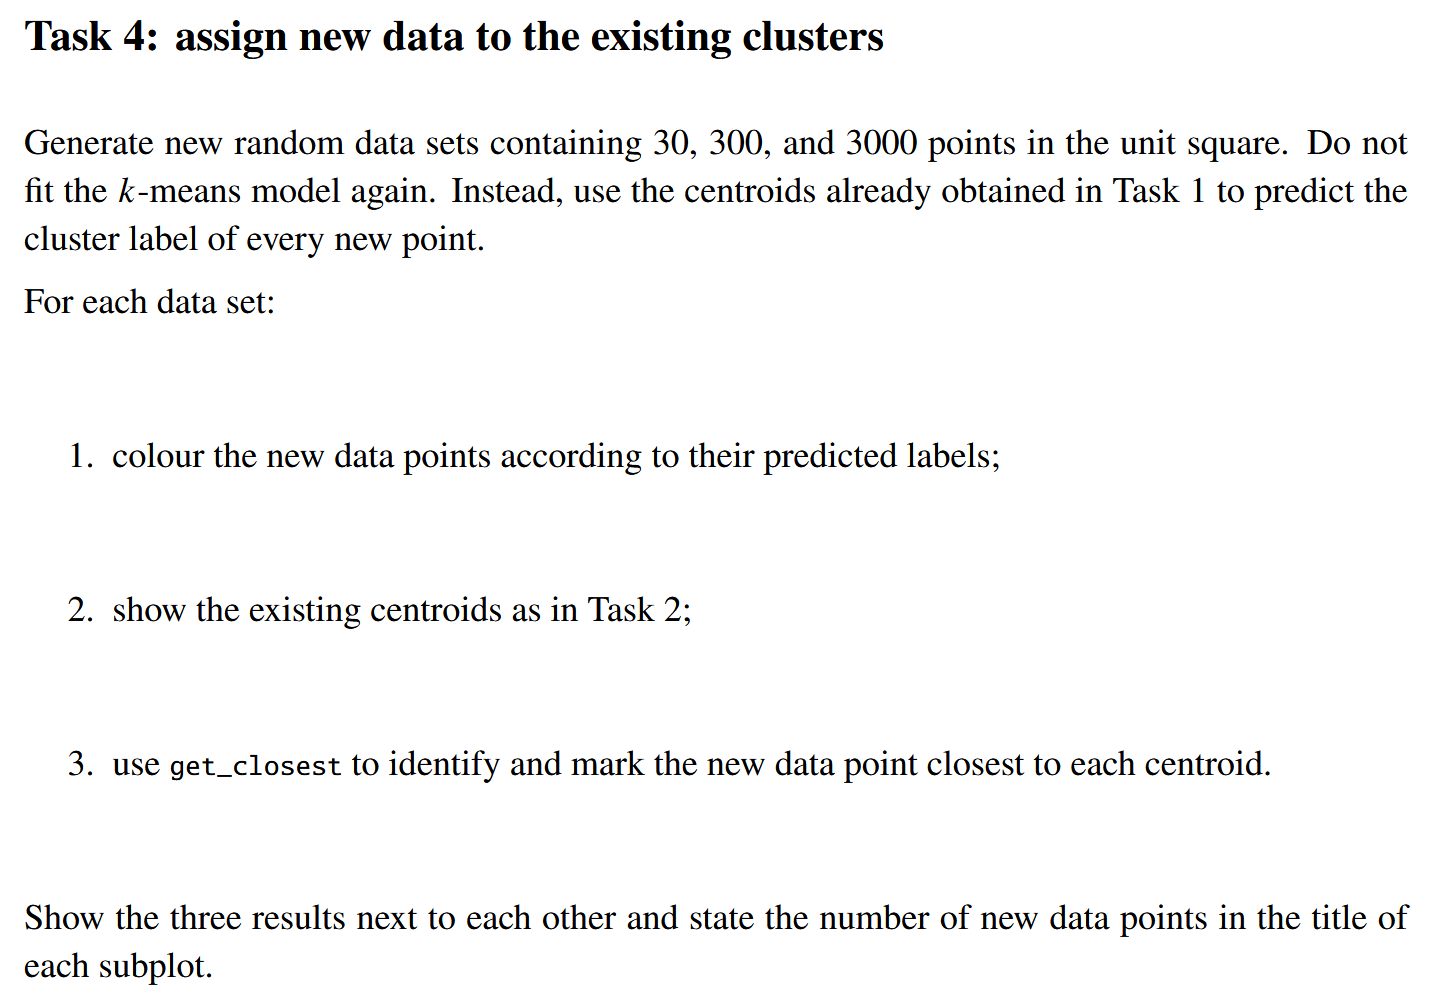

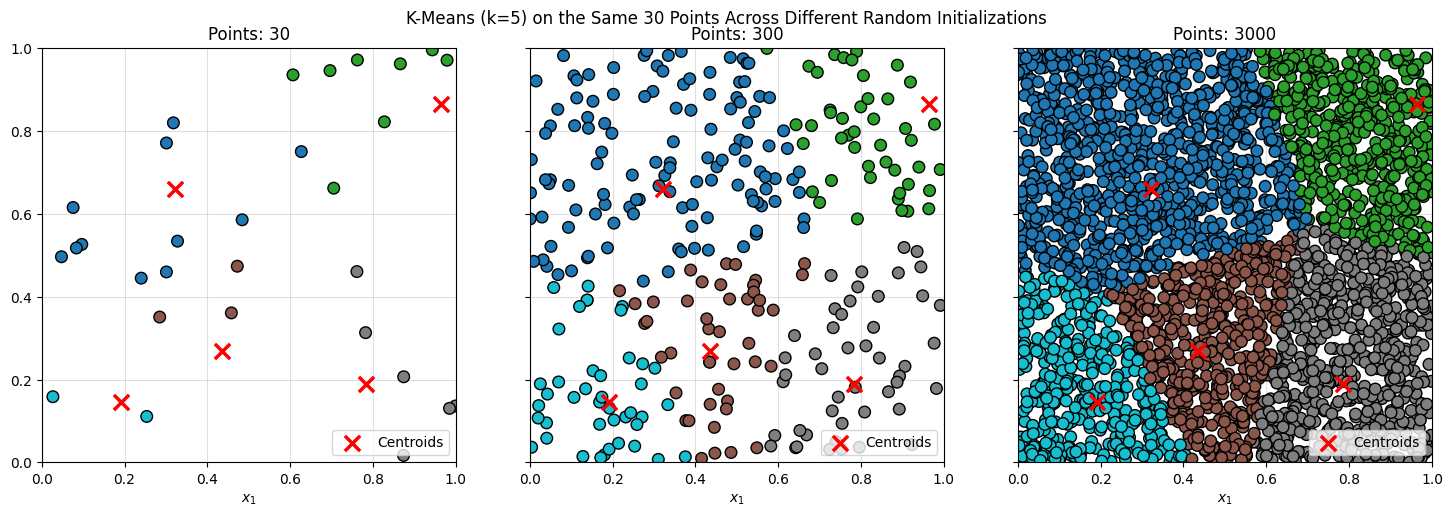

In [ ]:


fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

for N, ax in zip([30, 300, 3000], axes):
    X = np.random.rand(N, 2)
    labels = kmeans.predict(X)
    
    # Plot points coloured by their cluster labels
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=70, edgecolor='k', zorder=2)
    
    # Also plot the final cluster centroids as red 'X' markers
    ax.scatter(kmeans.mu[:, 0], kmeans.mu[:, 1], c='red', marker='x', s=120, linewidths=2.5, label='Centroids', zorder=3)
    
    ax.set_title(f'Points: {N}')
    ax.set_xlabel('$x_1$')
    if run_idx == 0:
        ax.set_ylabel('$x_2$')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.4)
    ax.legend(loc='lower right')

plt.suptitle('K-Means (k=5) on the Same Initializations')
plt.tight_layout()
plt.show()